# 全连接神经网络的实现

In [13]:
from sklearn.datasets import load_iris, load_wine
from torch.utils.data import Dataset, DataLoader   # 数据集的统一处理与分批次处理
from torch import nn     # 面向对象的封装
from torch import optim  # 梯度更新的封装
import torch

In [20]:
load_wine()

{'data': array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
         1.065e+03],
        [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
         1.050e+03],
        [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
         1.185e+03],
        ...,
        [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
         8.350e+02],
        [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
         8.400e+02],
        [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
         5.600e+02]], shape=(178, 13)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

## 1. 数据集

In [14]:
class IrisDataset(Dataset):
    """
    类的文档注释
    """
    def __init__(self):
        #调用父类构造器
        super(IrisDataset, self).__init__()   # python ABC
        # 加载数据
        # data, target = load_iris(return_X_y=True)
        data, target = load_wine(return_X_y=True)
        # 转换为张量
        self.x = torch.tensor(data[:], dtype=torch.float32)
        self.y = torch.tensor(target[:], dtype=torch.long).view(-1)

    def __getitem__(self, idx):
        """
        重载[]运算符
        参数：
            idx：访问数据的下标
        返回：
            指定位置的数据，样本与标签
        """
        return self.x[idx], self.y[idx]

    def __len__(self):
        return self.x.shape[0]   # len(self.x)

## 2. 模型实现

In [16]:
class MultiClassifyModel(nn.Module):

    def __init__(self, feature_dim, class_sample):
        super().__init__()
        # 输入层
        self.fc1 = nn.Linear(feature_dim, 12)
        # 隐藏层
        self.fc2 = nn.Linear(12, 6)
        # 输出层
        self.fc3 = nn.Linear(6, class_sample)
        # 激活函数
        self.activate = nn.ReLU()
        # 概率映射
        self.prob = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.activate(x)

        x = self.fc2(x)
        x = self.activate(x)
        
        x = self.fc3(x)
        x = self.prob(x)
        return x

## 3. 训练

In [21]:
@torch.no_grad
def evaluate(model, loader):
    model.to(device)
    num_sample = 0
    num_current = 0
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        y_ = model(x)

        # 判定，统计每分类下的最大概率的下标
        cls_ids = y_.argmax(dim=1)
        num_current += (y == cls_ids).float().sum()
        num_sample += len(x)
    return num_current / num_sample

def train(model, loader, loss_f, optimizer, epoch=10000):
    model.to(device)
    for e in range(epoch):
        for x, y in loader:
            optimizer.zero_grad()
            x = x.to(device)
            y = y.to(device)
            y_ = model(x)
            loss = loss_f(y_, y) # 交叉熵怎么处理真实标签与向量类型的不匹配
            loss.backward()
            optimizer.step()
            
        if e % 1000 == 0:
            current_rate = evaluate(model, loader)
            print(f"轮数{e:05d}, 损失值:{loss.cpu().item():.6f}，准确率:{current_rate.cpu().item()* 100: .6f}%")

epoch = 10000
lr = 0.001

ds = IrisDataset()
loader = DataLoader(ds, batch_size=30, shuffle=True)

model = MultiClassifyModel(13, 3)

loss_f = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    params=model.parameters(),  # 取出模型所有的参数， 也是优化器更新的目标
    lr=lr
)

device = "cuda:0" if torch.cuda.is_available() else "cpu"
model.to(device) # 移动模型到设备

MultiClassifyModel(
  (fc1): Linear(in_features=13, out_features=12, bias=True)
  (fc2): Linear(in_features=12, out_features=6, bias=True)
  (fc3): Linear(in_features=6, out_features=3, bias=True)
  (activate): ReLU()
  (prob): Softmax(dim=1)
)

In [ ]:
train(model, loader, loss_f, optimizer)

# 激活函数可视化

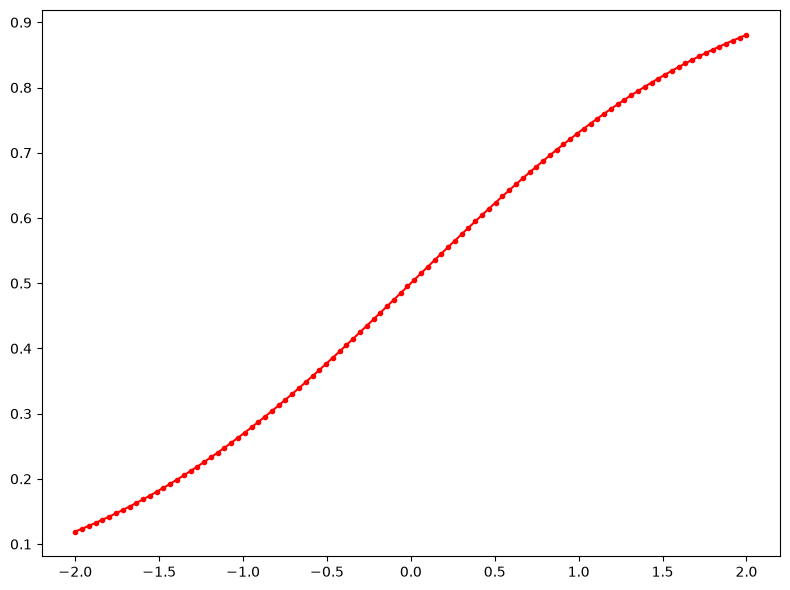

In [31]:
import torch
import matplotlib.pyplot as plt

# 数据
x = torch.linspace(-2, 2, 100)  # 生成100个点在-2到2之间， 返回的是张量
y = torch.nn.functional.sigmoid(x)
# act = torch.nn.ReLU()
# y = act(x) 

# 可视化

## 图
plt.figure(figsize=(8, 6))
## 坐标系
## 绘图
plt.plot(x, y, "r.-")
## 布局
plt.tight_layout()
## 显示
plt.show()